# AgroPest-12: Dataset Exploration & Preprocessing

**Student:** Md. Sadik Shahriar  
**ID** 2023-2-60-103
**Dataset:** AgroPest-12-Cleaned &mdash; Image Dataset for Crop Pest Detection  
**Course:** CSE 445 &mdash; Computer Vision | Assignment 1  

This notebook performs **Exploratory Data Analysis (EDA)** on the AgroPest-12cleaned crop pest dataset.  


In [1]:
# ============================================================
# CONFIG — All paths, class names, and key parameters
# ============================================================
import os

# Kaggle dataset paths
DATASET_PATH = "/kaggle/input/datasets/sadikshahriar/agropest-12-cleaned/AgroPest-12-Cleaned"
TRAIN_IMG = os.path.join(DATASET_PATH, "train", "images")
TRAIN_LBL = os.path.join(DATASET_PATH, "train", "labels")
VALID_IMG = os.path.join(DATASET_PATH, "valid", "images")
VALID_LBL = os.path.join(DATASET_PATH, "valid", "labels")
TEST_IMG  = os.path.join(DATASET_PATH, "test", "images")
TEST_LBL  = os.path.join(DATASET_PATH, "test", "labels")

# Class names (YOLO format: 0-indexed)
CLASS_NAMES = {
    0: "Ants", 1: "Bees", 2: "Beetles", 3: "Caterpillars",
    4: "Earthworms", 5: "Earwigs", 6: "Grasshoppers", 7: "Moths",
    8: "Slugs", 9: "Snails", 10: "Wasps", 11: "Weevils"
}
NUM_CLASSES = 12

# Image parameters
IMAGE_SIZE = 640  # dataset native resolution

# COCO small / medium / large thresholds (area in pixels²)
COCO_SMALL  = 32**2      # < 1024 px²
COCO_MEDIUM = 96**2      # 1024–9216 px²

# Output directory for saved artifacts
OUTPUT_DIR = "/kaggle/working"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("CONFIG loaded — 12 classes | 640×640 images | pre-split dataset")

CONFIG loaded — 12 classes | 640×640 images | pre-split dataset


In [2]:
# ============================================================
# Imports & Plot Styling
# ============================================================
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import cv2
from pathlib import Path
from collections import Counter, defaultdict
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.rcParams.update({
    'figure.dpi': 100,
    'savefig.dpi': 100,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})
sns.set_style("whitegrid")

# Distinct colors for 12 classes
CLASS_COLORS = [
    "#e6194b", "#3cb44b", "#ffe119", "#4363d8",
    "#f58231", "#911eb4", "#46f0f0", "#f032e6",
    "#bcf60c", "#fabebe", "#008080", "#e6beff"
]

print("Libraries imported.")

Libraries imported.


## 1. Dataset Overview

AgroPest-12 is a curated dataset of crop pest images captured in natural agricultural environments.
Each image has corresponding YOLO-format bounding box annotations (`<class_id> <cx> <cy> <w> <h>` with
normalised coordinates). The dataset arrives **pre-split** into training, validation, and test
directories. The following cell verifies file counts, label–image pairing, and checks for corrupt
files before proceeding to EDA.

In [3]:
# ============================================================
# Task 5.1 — Dataset Integrity Check
# ============================================================
def check_split(img_dir, lbl_dir, split_name, spot_check=200):
    """Count images/labels, detect orphans, spot-check for corrupt JPEGs."""
    imgs = sorted([f for f in os.listdir(img_dir)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    lbls = sorted([f for f in os.listdir(lbl_dir)
                   if f.lower().endswith('.txt')])

    img_stems = {os.path.splitext(f)[0] for f in imgs}
    lbl_stems = {os.path.splitext(f)[0] for f in lbls}

    orphan_imgs = img_stems - lbl_stems  # image with no label
    orphan_lbls = lbl_stems - img_stems  # label with no image

    corrupt = 0
    for f in imgs[:spot_check]:
        img = cv2.imread(os.path.join(img_dir, f))
        if img is None:
            corrupt += 1

    print(f"{split_name:>6}: {len(imgs):>6} imgs | {len(lbls):>6} lbls | "
          f"orphan I={len(orphan_imgs)} L={len(orphan_lbls)} | corrupt≈{corrupt}")

    return {
        "split": split_name,
        "images": len(imgs),
        "labels": len(lbls),
        "orphan_images": len(orphan_imgs),
        "orphan_labels": len(orphan_lbls),
        "corrupt_spotted": corrupt,
    }

results = []
for path_tuple, name in [
    ((TRAIN_IMG, TRAIN_LBL), "train"),
    ((VALID_IMG, VALID_LBL), "valid"),
    ((TEST_IMG,  TEST_LBL),  "test"),
]:
    results.append(check_split(*path_tuple, name))

df = pd.DataFrame(results).set_index("split")
total_imgs = df["images"].sum()
total_lbls = df["labels"].sum()
print(f"\n│ Total: {total_imgs} images, {total_lbls} labels │")
display(df)

 train:  11475 imgs |  11475 lbls | orphan I=0 L=0 | corrupt≈0
 valid:   1089 imgs |   1089 lbls | orphan I=0 L=0 | corrupt≈0
  test:    543 imgs |    543 lbls | orphan I=0 L=0 | corrupt≈0

│ Total: 13107 images, 13107 labels │


,images,labels,orphan_images,orphan_labels,corrupt_spotted
split,,,,,
train,11475,11475,0,0,0
valid,1089,1089,0,0,0
test,543,543,0,0,0


## 2. Class Distribution

Parsing every label file across the **training set** to count per-class bounding-box instances.
A highly imbalanced dataset would influence augmentation choices (e.g., enabling mosaic or
mixup to up-sample rare classes) and the choice of loss function (focal vs. standard).

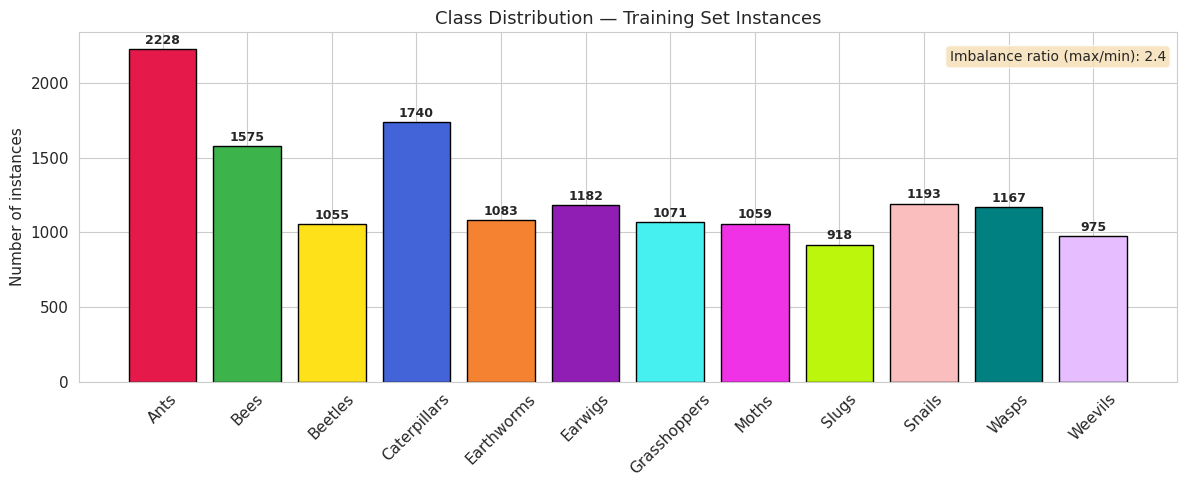

,Instances
Class,
Ants,2228
Bees,1575
Beetles,1055
Caterpillars,1740
Earthworms,1083
Earwigs,1182
Grasshoppers,1071
Moths,1059
Slugs,918


In [4]:
# ============================================================
# Task 5.1 — Class Distribution (instance count per class)
# ============================================================

def count_instances(lbl_dir):
    """Count per-class instance totals from all .txt label files."""
    counter = Counter()
    lbl_files = [f for f in os.listdir(lbl_dir) if f.endswith('.txt')]
    for fname in tqdm(lbl_files, desc="Parsing labels", leave=False):
        with open(os.path.join(lbl_dir, fname), 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls_id = int(float(parts[0]))
                    counter[cls_id] += 1
    return counter

# Count instances in training set
train_counts = count_instances(TRAIN_LBL)

# Build DataFrame
rows = []
for cls_id in sorted(CLASS_NAMES.keys()):
    rows.append({
        "Class": CLASS_NAMES[cls_id],
        "Instances": train_counts.get(cls_id, 0),
    })
df_cls = pd.DataFrame(rows).set_index("Class")

# Bar chart
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(df_cls.index, df_cls["Instances"],
              color=[CLASS_COLORS[i] for i in range(NUM_CLASSES)], edgecolor='black')

ax.set_title("Class Distribution — Training Set Instances")
ax.set_ylabel("Number of instances")
ax.tick_params(axis='x', rotation=45)

# Annotate bars
for bar, val in zip(bars, df_cls["Instances"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 15,
            str(val), ha='center', va='bottom', fontsize=9, fontweight='bold')

# Imbalance note
max_val = df_cls["Instances"].max()
min_val = df_cls["Instances"].min()
imbalance_ratio = max_val / min_val if min_val > 0 else float('inf')
ax.text(0.99, 0.95, f"Imbalance ratio (max/min): {imbalance_ratio:.1f}",
        transform=ax.transAxes, ha='right', va='top',
        fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"))
plt.show()

display(df_cls)

## 3. Image Properties

Spot-checking image resolution, aspect ratio, and file format across the dataset.  
The dataset documentation states all images are **640×640 JPEG**, but we verify this
empirically. Any deviation from square would require rectangular training (`rect=True`).

Scanning images: 100%|██████████| 1500/1500 [00:11<00:00, 126.46it/s]


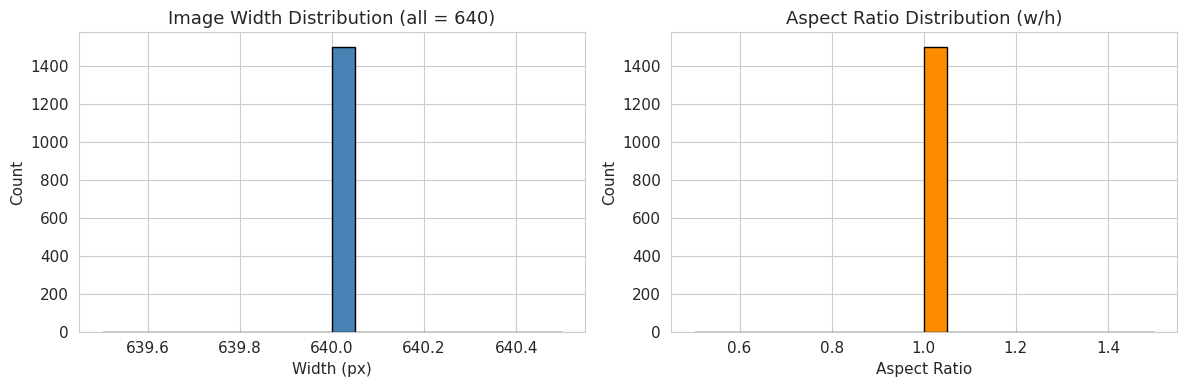

File formats found: {'.jpg'}
Unique resolutions: {(640, 640)}
Aspect ratio range: [1.000, 1.000]


In [5]:
# ============================================================
# Task 5.1 — Image Properties (resolution, aspect ratio, format)
# ============================================================

# Sample across all three splits for a representative view
sample_paths = []
for img_dir in [TRAIN_IMG, VALID_IMG, TEST_IMG]:
    imgs = sorted([f for f in os.listdir(img_dir)
                   if f.lower().endswith(('.jpg', '.jpeg', '.png'))])
    sample_paths += [os.path.join(img_dir, f) for f in imgs[:500]]  # 500 per split

resolutions = []
aspects = []
formats = set()
for p in tqdm(sample_paths, desc="Scanning images"):
    img = cv2.imread(p)
    if img is not None:
        h, w = img.shape[:2]
        resolutions.append((w, h))
        aspects.append(w / h)
        ext = os.path.splitext(p)[1].lower()
        formats.add(ext)

res_arr = np.array(resolutions)
asp_arr = np.array(aspects)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Width distribution
axes[0].hist(res_arr[:, 0], bins=20, color='steelblue', edgecolor='black')
axes[0].set_title("Image Width Distribution (all = 640)")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Count")

# Aspect ratio
axes[1].hist(asp_arr, bins=20, color='darkorange', edgecolor='black')
axes[1].set_title("Aspect Ratio Distribution (w/h)")
axes[1].set_xlabel("Aspect Ratio")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "image_properties.png"))
plt.show()

print(f"File formats found: {formats}")
print(f"Unique resolutions: {set(tuple(r) for r in resolutions)}")
print(f"Aspect ratio range: [{asp_arr.min():.3f}, {asp_arr.max():.3f}]")

## 4. Bounding Box Statistics

Analysing box count per image, width / height / area distributions, and the proportion of
small vs. medium vs. large objects (using COCO thresholds: **small < 32²**, **medium 32²–96²**,
**large > 96²**). This directly influences model size selection and input resolution: a
dataset dominated by small objects benefits from higher resolution or a larger model.

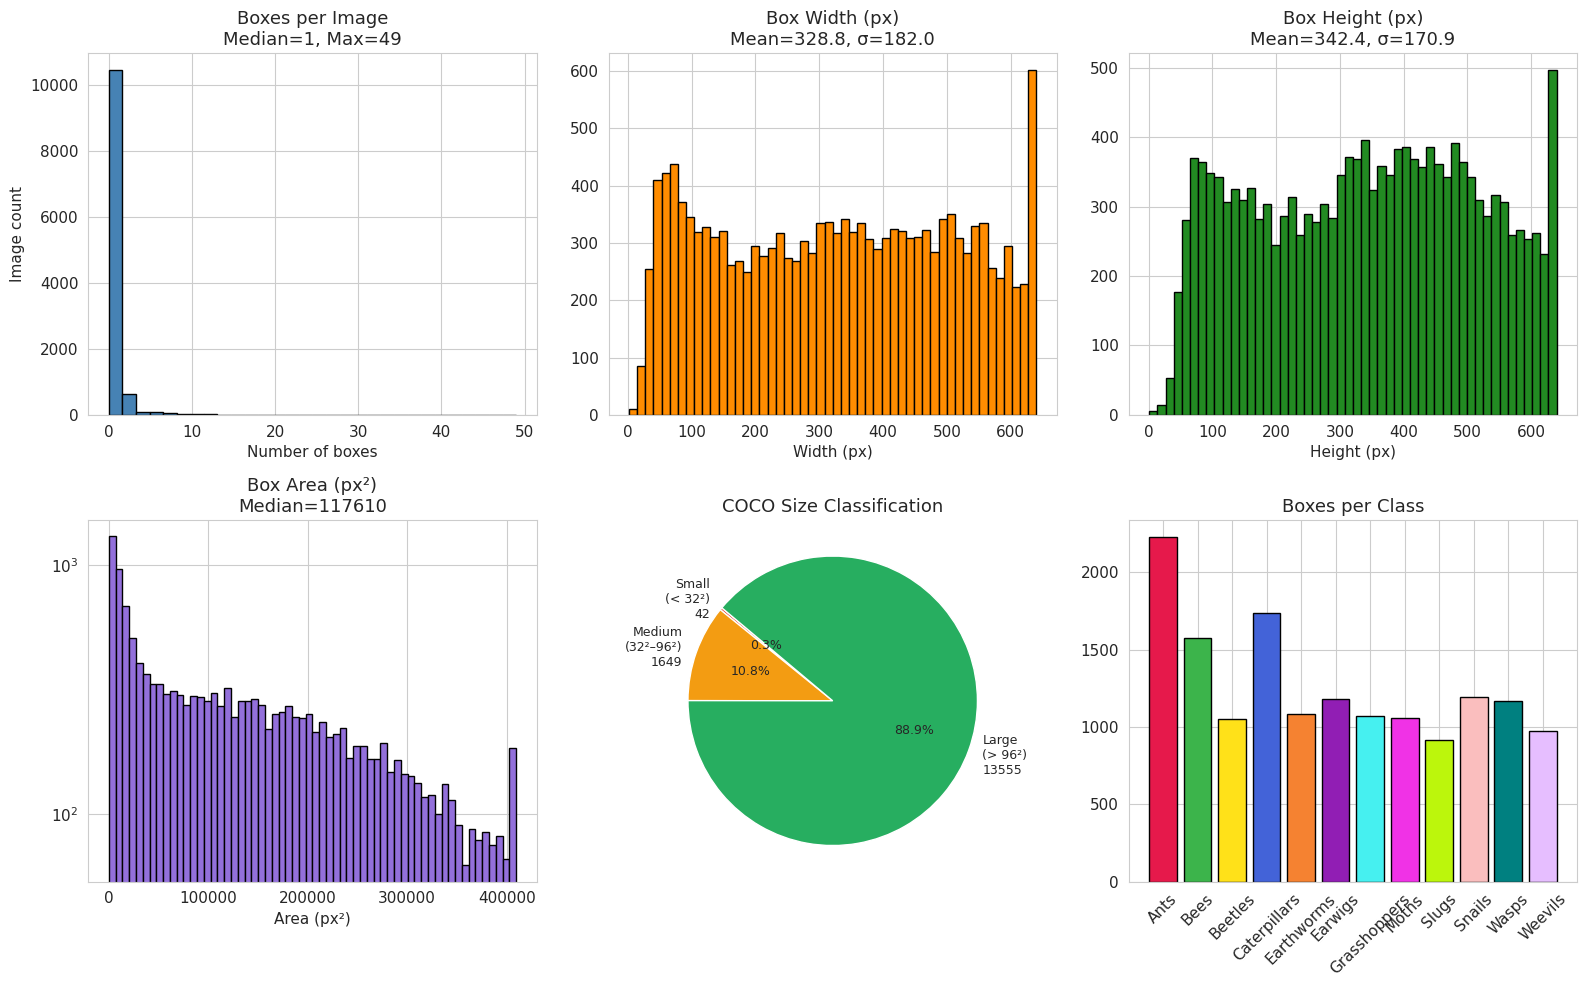

Total boxes parsed: 15246
Small  (<  1024 px²):     42  (0.3%)
Medium ( 1024–9216 px²):   1649  (10.8%)
Large  (>  9216 px²):  13555  (88.9%)
Boxes-per-image: median=1.0, mean=1.33, max=49


In [6]:
# ============================================================
# Task 5.1 — Bounding Box Statistics
# ============================================================

def parse_all_boxes(lbl_dir):
    """Parse every .txt label file and return arrays of [w, h, area, cls_id]."""
    all_w, all_h, all_area, all_cls = [], [], [], []
    boxes_per_img = []
    lbl_files = [f for f in os.listdir(lbl_dir) if f.endswith('.txt')]
    for fname in tqdm(lbl_files, desc="Parsing boxes", leave=False):
        count = 0
        with open(os.path.join(lbl_dir, fname), 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls_id = int(float(parts[0]))
                    cx, cy, bw, bh = map(float, parts[1:5])
                    # Normalised -> absolute pixels (640 px)
                    w_abs = bw * IMAGE_SIZE
                    h_abs = bh * IMAGE_SIZE
                    area = w_abs * h_abs
                    all_w.append(w_abs)
                    all_h.append(h_abs)
                    all_area.append(area)
                    all_cls.append(cls_id)
                    count += 1
        boxes_per_img.append(count)
    return (np.array(all_w), np.array(all_h), np.array(all_area),
            np.array(all_cls), np.array(boxes_per_img))

# Parse training set
w_arr, h_arr, area_arr, cls_arr, boxes_per_img = parse_all_boxes(TRAIN_LBL)

# COCO size classification (absolute px on 640×640)
small_mask  = area_arr < COCO_SMALL
medium_mask = (area_arr >= COCO_SMALL) & (area_arr <= COCO_MEDIUM)
large_mask  = area_arr > COCO_MEDIUM

n_small  = small_mask.sum()
n_medium = medium_mask.sum()
n_large  = large_mask.sum()
total_boxes = len(area_arr)

# --- Subplot layout ---
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# A) Boxes-per-image histogram
axes[0, 0].hist(boxes_per_img, bins=30, color='steelblue', edgecolor='black')
axes[0, 0].set_title(f"Boxes per Image\nMedian={np.median(boxes_per_img):.0f}, Max={boxes_per_img.max()}")
axes[0, 0].set_xlabel("Number of boxes")
axes[0, 0].set_ylabel("Image count")

# B) Box width distribution
axes[0, 1].hist(w_arr, bins=50, color='darkorange', edgecolor='black')
axes[0, 1].set_title(f"Box Width (px)\nMean={w_arr.mean():.1f}, σ={w_arr.std():.1f}")
axes[0, 1].set_xlabel("Width (px)")

# C) Box height distribution
axes[0, 2].hist(h_arr, bins=50, color='forestgreen', edgecolor='black')
axes[0, 2].set_title(f"Box Height (px)\nMean={h_arr.mean():.1f}, σ={h_arr.std():.1f}")
axes[0, 2].set_xlabel("Height (px)")

# D) Box area distribution (log scale)
axes[1, 0].hist(area_arr, bins=60, color='mediumpurple', edgecolor='black')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title(f"Box Area (px²)\nMedian={np.median(area_arr):.0f}")
axes[1, 0].set_xlabel("Area (px²)")

# E) COCO size pie
sizes = [n_small, n_medium, n_large]
labels_pie = [f"Small\n(< 32²)\n{n_small}",
              f"Medium\n(32²–96²)\n{n_medium}",
              f"Large\n(> 96²)\n{n_large}"]
colors_pie = ["#e74c3c", "#f39c12", "#27ae60"]
axes[1, 1].pie(sizes, labels=labels_pie, colors=colors_pie,
              autopct='%1.1f%%', startangle=140, textprops={'fontsize': 9})
axes[1, 1].set_title("COCO Size Classification")

# F) Boxes per class (training set)
per_cls_boxes = {cid: (cls_arr == cid).sum() for cid in range(NUM_CLASSES)}
cls_names = [CLASS_NAMES[i] for i in range(NUM_CLASSES)]
cls_counts = [per_cls_boxes[i] for i in range(NUM_CLASSES)]
axes[1, 2].bar(cls_names, cls_counts, color=[CLASS_COLORS[i] for i in range(NUM_CLASSES)], edgecolor='black')
axes[1, 2].set_title("Boxes per Class")
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "bbox_statistics.png"))
plt.show()

# Summary table
print(f"Total boxes parsed: {total_boxes}")
print(f"Small  (< {COCO_SMALL:>5} px²): {n_small:>6}  ({100*n_small/total_boxes:.1f}%)")
print(f"Medium ( {COCO_SMALL}–{COCO_MEDIUM} px²): {n_medium:>6}  ({100*n_medium/total_boxes:.1f}%)")
print(f"Large  (> {COCO_MEDIUM:>5} px²): {n_large:>6}  ({100*n_large/total_boxes:.1f}%)")
print(f"Boxes-per-image: median={np.median(boxes_per_img):.1f}, mean={boxes_per_img.mean():.2f}, max={boxes_per_img.max()}")

## 5. Annotated Sample Images

Visualising ground-truth bounding boxes overlaid on sample images from the training set.
Boxes are **colour-coded by class** to give a qualitative sense of object size, density,
and class co-occurrence within a single image.

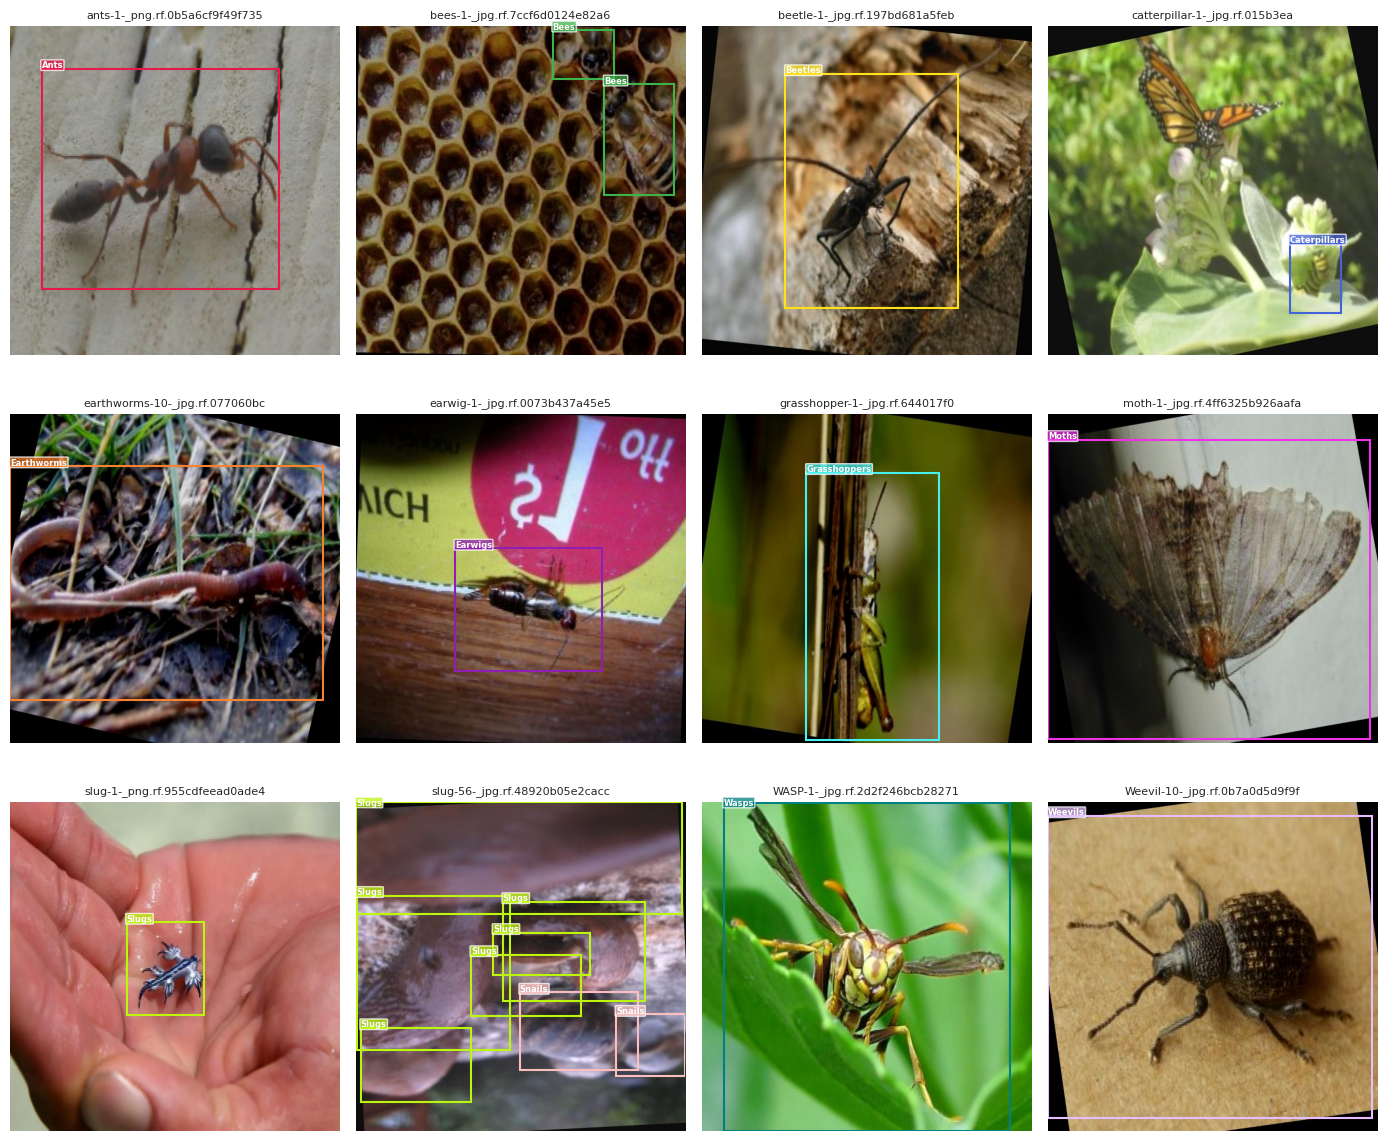

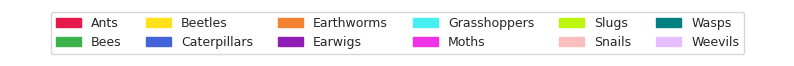

In [7]:
# ============================================================
# Task 5.1 — Annotated Sample Visualisation
# ============================================================

def draw_boxes(img_path, lbl_path, ax):
    """Load image, parse labels, draw colour-coded boxes."""
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    ax.imshow(img)
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls_id = int(float(parts[0]))
            cx, cy, bw, bh = map(float, parts[1:5])
            x1 = int((cx - bw / 2) * w)
            y1 = int((cy - bh / 2) * h)
            box_w = int(bw * w)
            box_h = int(bh * h)

            color = CLASS_COLORS[cls_id]
            rect = mpatches.Rectangle((x1, y1), box_w, box_h,
                                      fill=False, edgecolor=color, linewidth=1.5)
            ax.add_patch(rect)
            ax.text(x1, max(y1 - 2, 6), CLASS_NAMES[cls_id],
                    fontsize=6, color='white', weight='bold',
                    bbox=dict(boxstyle='round,pad=0.1', facecolor=color, alpha=0.75))

    ax.axis('off')

# Gather diverse samples: up to 2 images per class
imgs_available = sorted(os.listdir(TRAIN_IMG))
collected = {i: [] for i in range(NUM_CLASSES)}
for fname in imgs_available:
    if all(len(v) >= 2 for v in collected.values()):
        break
    lbl_fname = os.path.splitext(fname)[0] + '.txt'
    lbl_path = os.path.join(TRAIN_LBL, lbl_fname)
    if not os.path.exists(lbl_path):
        continue
    # Determine which classes are in this image
    cls_in_img = set()
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 5:
                cls_in_img.add(int(float(parts[0])))
    for cid in cls_in_img:
        if len(collected[cid]) < 2:
            collected[cid].append((os.path.join(TRAIN_IMG, fname), lbl_path))
            break  # one image can cover multiple classes, but don't reuse too much

# Build flat list of up to 16 samples
sample_pairs = []
for cid in range(NUM_CLASSES):
    if collected[cid]:
        sample_pairs.append(collected[cid][0])
sample_pairs = sample_pairs[:16]

n_cols = 4
n_rows = (len(sample_pairs) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]

for i, (img_path, lbl_path) in enumerate(sample_pairs):
    draw_boxes(img_path, lbl_path, axes[i])
    axes[i].set_title(os.path.basename(img_path)[:30], fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "annotated_samples.png"), dpi=150)
plt.show()

# Legend
legend_patches = [mpatches.Patch(color=CLASS_COLORS[i], label=CLASS_NAMES[i])
                  for i in range(NUM_CLASSES)]
fig_leg = plt.figure(figsize=(10, 0.6))
fig_leg.legend(handles=legend_patches, loc='center', ncol=6, fontsize=9)
plt.axis('off')
plt.show()